# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import NZCattleDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv

## Visualize images and objects witn bounding boxes

Total number of patches: 655


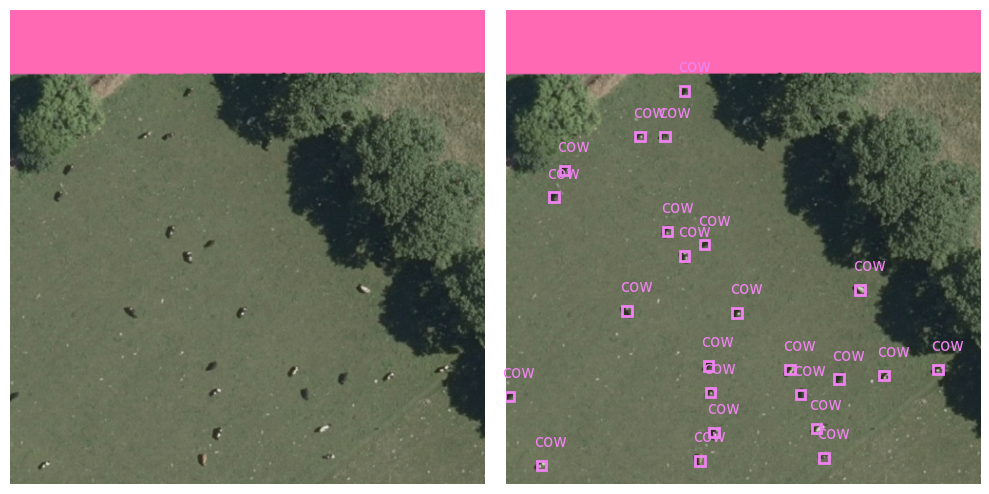

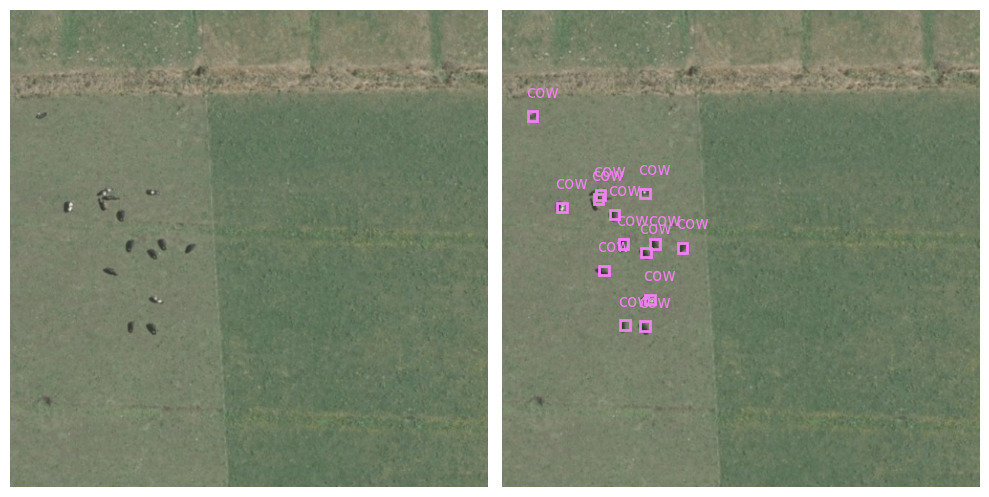

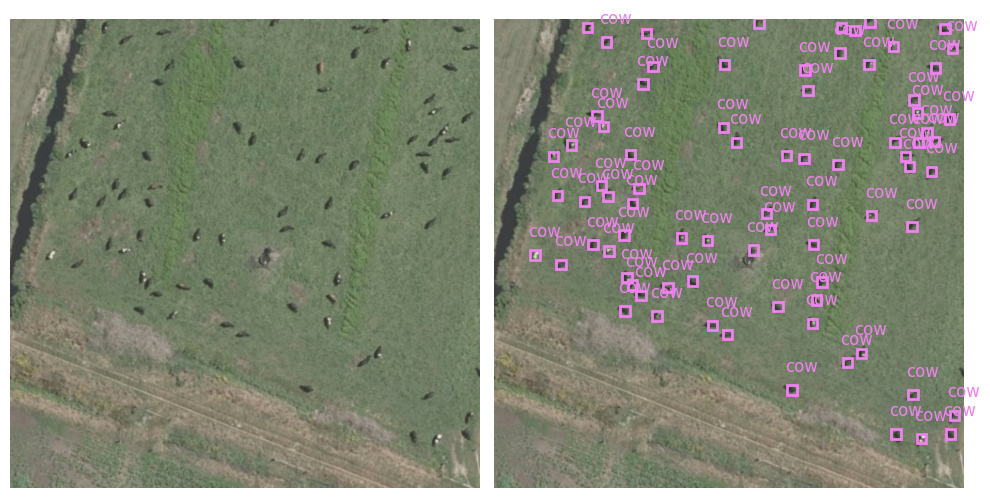

In [ ]:
dataset_config = {
    "data_dir": "./data/NZ_cattle/cow_images/",
    "annotation_dir": "./data/NZ_cattle/annotations/"
}
dataset = NZCattleDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(90);

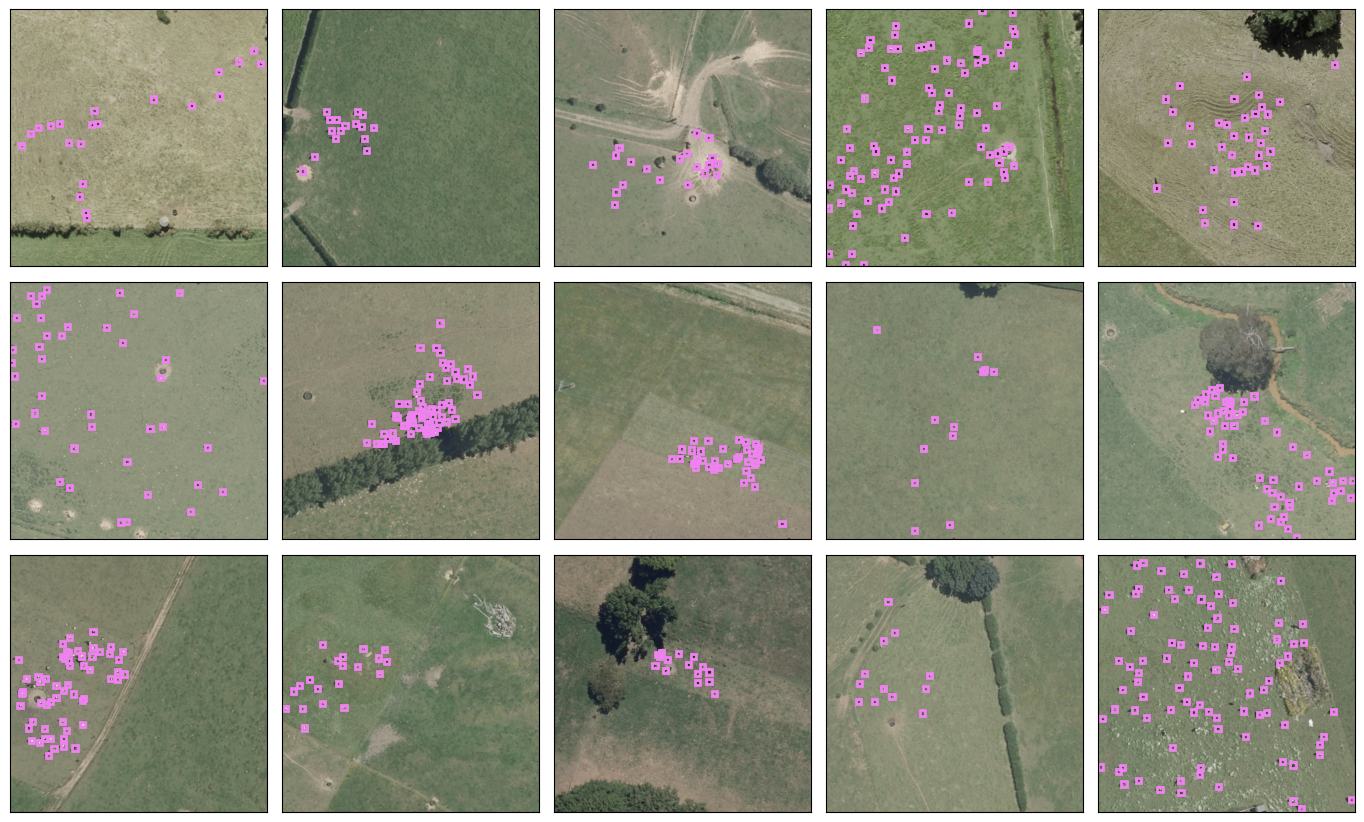

In [19]:
dataset.show_batch(15);

In [20]:
dataset.data_distribution_table()

,Label,Count
0,cow,29803


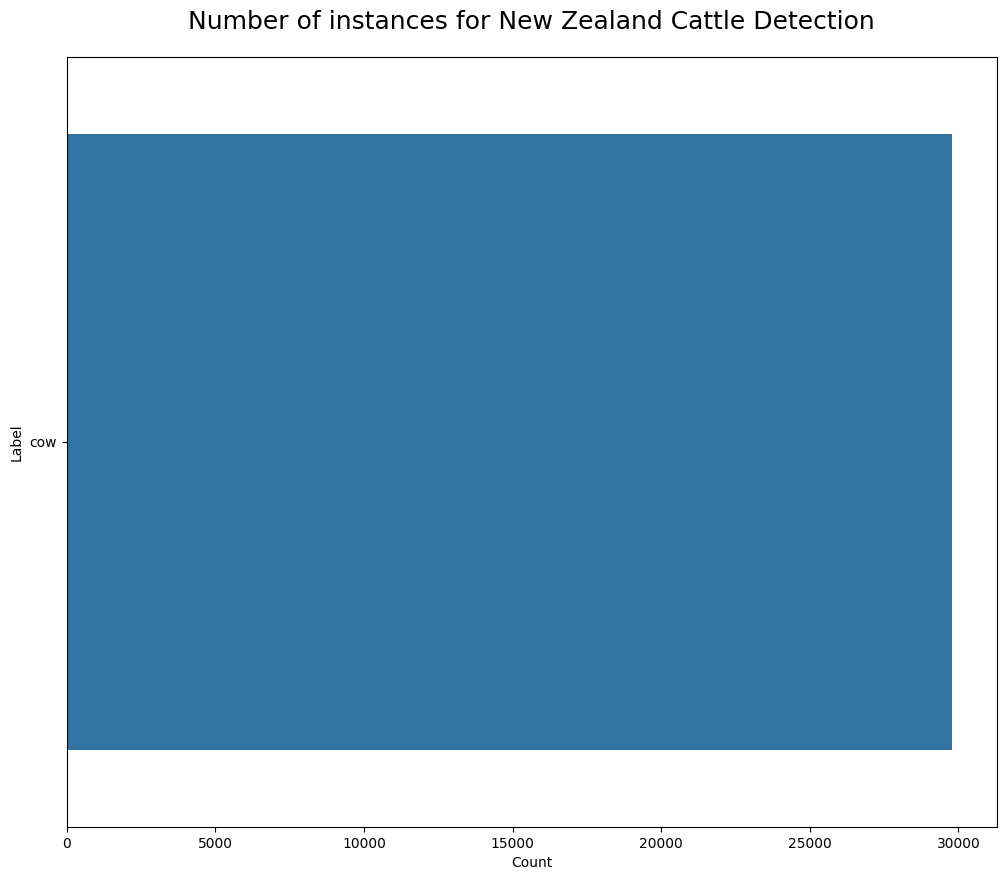

In [21]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/NZ_cattle/cow_images/",
    "annotation_dir": "./data/NZ_cattle/annotations/",
    "csv_file": "./data/NZ_cattle/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = NZCattleDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 525


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/NZ_cattle/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [46]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-09-04 11:31:01,761 INFO Starting training.
training: 100%|██████████| 66/66 [00:23<00:00,  2.82it/s]
2025-09-04 11:31:25,214 INFO epoch: 1, time: 24, loss:  0.74951
testing on train set: 100%|██████████| 66/66 [00:12<00:00,  5.34it/s]
2025-09-04 11:32:39,561 INFO map:0.25829291343688965, map_50:0.6704748272895813, map_75:0.13722677528858185, map_small:0.25829291343688965, map_medium:-1.0, map_large:-1.0, mar_1:0.011301008984446526, mar_10:0.09632021188735962, mar_100:0.36312612891197205, mar_small:0.36312612891197205, mar_medium:-1.0, mar_large:-1.0, map_per_class:0.25829291343688965, mar_100_per_class:0.36312612891197205, classes:1.0
training: 100%|██████████| 66/66 [00:23<00:00,  2.86it/s]
2025-09-04 11:33:02,607 INFO epoch: 2, time: 23, loss:  0.49374
testing on train set: 100%|██████████| 66/66 [00:13<00:00,  5.07it/s]
2025-09-04 11:33:51,153 INFO map:0.27309155464172363, map_50:0.697412371635437, map_75:0.1492859423160553, map_small:0.27309155464172363, map_medium:-1.0, map_l

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/NZ_cattle/cow_images/",
    "annotation_dir": "./data/NZ_cattle/annotations",
    "csv_file": "./data/NZ_cattle/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = NZCattleDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/NZ_cattle/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 65


2025-09-04 11:44:21,248 INFO Loading checkpoint /home/dragik/data/FAIR_EO/NZ_cattle/experiments/checkpoint.pth.tar
2025-09-04 11:44:21,550 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/NZ_cattle/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 9/9 [00:02<00:00,  3.36it/s]


[{'map': 0.2692286968231201,
  'map_50': 0.6724318265914917,
  'map_75': 0.1585475355386734,
  'map_small': 0.2692286968231201,
  'map_medium': -1.0,
  'map_large': -1.0,
  'mar_1': 0.01147000677883625,
  'mar_10': 0.09660514444112778,
  'mar_100': 0.37686222791671753,
  'mar_small': 0.37686222791671753,
  'mar_medium': -1.0,
  'mar_large': -1.0,
  'map_per_class': 0.2692286968231201,
  'mar_100_per_class': 0.37686222791671753,
  'classes': 1.0}]

## Predictions

2025-09-04 11:45:02,246 INFO Loading checkpoint /home/dragik/data/FAIR_EO/NZ_cattle/experiments/checkpoint.pth.tar
2025-09-04 11:45:02,549 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/NZ_cattle/experiments/checkpoint.pth.tar at epoch 11


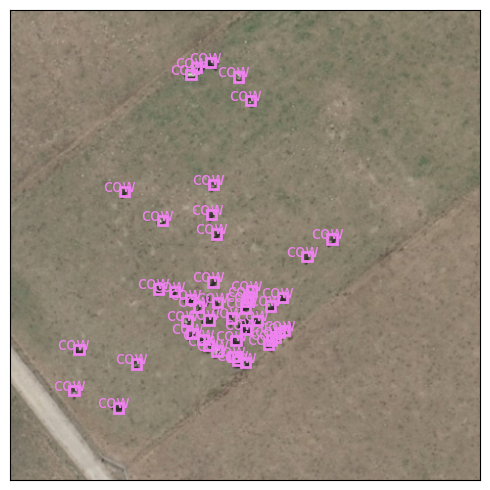

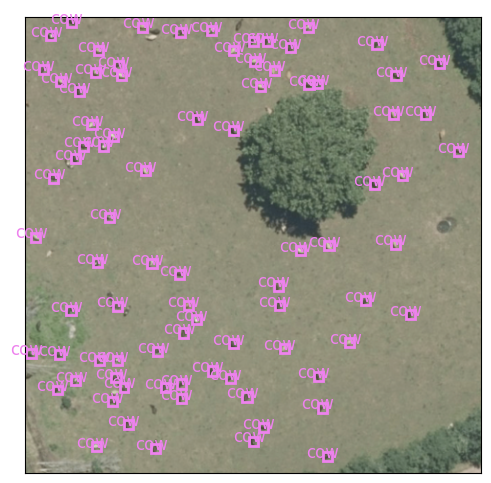

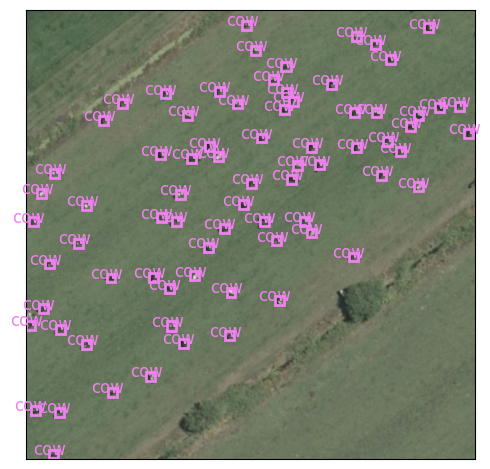

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/NZ_cattle/experiments/checkpoint.pth.tar"
labels = ["no-data", "cow"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/NZ_cattle/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0]+','+lines[1])

image = image_loader('./data/NZ_cattle/' + test_list[0])
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/NZ_cattle/' + test_list[5])
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/NZ_cattle/' + test_list[7])
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)